# Job Market Skills and Salary Analysis
## JobScope India · DA-021

This reproducible notebook analyses the supplied job-posting dataset. Results are calculated at run time; no findings are hardcoded.

## Objectives
Identify job roles, locations, structured skills, stated experience and disclosed salary coverage to support evidence-based career-learning discussions.

## Dataset source and description
Fliar BI, *Job Postings 2026: India and United States*, Zenodo DOI 10.5281/zenodo.23432224 (CC BY-NC 4.0; published 2026-10-17). It is a 100,009-row sample of individual, deduplicated public postings collected from January–June 2026. The source includes annual USD salary, not INR. This notebook filters to India when available.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_loader import load_default_dataset, dataset_profile
from src.preprocessing import clean_job_data
from src.skills_analysis import skill_frequency, skills_by_role
from src.salary_analysis import salary_summary, salary_by_group
from src.location_analysis import location_counts
from src.experience_analysis import experience_distribution, entry_level_count


## Loading and initial exploration

In [2]:
raw = load_default_dataset()
profile = dataset_profile(raw)
print(f"Rows: {profile['rows']:,}; columns: {profile['columns']}")
raw.head()

Rows: 100,009; columns: 17


,posting_id,posted_date,title,company,role,seniority,category,city,region,country,remote,experience_years,education,skills,salary_annual_usd,company_domain,fliar_profile_url
0,0065c048923a,2026-01-01,Diagnostic Medical Sonographer,CCRM Fertility,healthcare,NaN,NaN,Austin,Texas,US,onsite,NaN,NaN,NaN,NaN,NaN,NaN
1,008365bc7d00,2026-01-01,"Neurologist Movement Disorders | Renton, WA | ...",The Provider Finder,NaN,NaN,NaN,Renton,Washington,US,onsite,NaN,NaN,NaN,NaN,NaN,NaN
2,00b93252154b,2026-01-01,Entry-Level Public Projects Engineer - Rail,Olsson,NaN,entry,NaN,Omaha,Nebraska,US,onsite,NaN,NaN,NaN,NaN,NaN,NaN
3,0115298b49e2,2026-01-01,Web Developer Job at Amicis Global in Scottsdale,Amicis Global,software-eng,NaN,NaN,Scottsdale,Arizona,US,onsite,NaN,NaN,NaN,NaN,NaN,NaN
4,016ada42b5ed,2026-01-01,Health Service Specialist,Rosecrance Health Network,healthcare,NaN,NaN,Rockford,Illinois,US,onsite,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
pd.DataFrame({'missing_values': raw.isna().sum(), 'missing_percent': raw.isna().mean().mul(100).round(1)}).sort_values('missing_values', ascending=False)

,missing_values,missing_percent
education,92175,92.2
salary_annual_usd,85190,85.2
experience_years,78013,78.0
skills,72067,72.1
fliar_profile_url,71628,71.6
company_domain,71405,71.4
category,67203,67.2
seniority,55464,55.5
remote,36438,36.4
role,27589,27.6


## Data cleaning
The reusable pipeline standardises text and headers, removes only invalid title-less rows and duplicates, retains missing values, standardises only structured skills, and flags extreme USD salaries without deleting them.

In [4]:
result = clean_job_data(raw)
cleaned, audit = result.data, result.audit
audit

,action,rows,reason
0,removed invalid records,0,missing job title
1,removed duplicates,847,duplicate posting ID or full row
2,flagged salary outliers,0,"annual USD < 1,000 or > 1,000,000; retained fo..."
3,retained missing salaries,84493,missing pay is not zero


In [5]:
india = cleaned[cleaned['country_clean'].eq('IN')].copy() if cleaned['country_clean'].eq('IN').any() else cleaned.copy()
print(f"Analysis rows: {len(india):,}")
Path(PROJECT_ROOT / 'data/processed').mkdir(parents=True, exist_ok=True)
india.to_csv(PROJECT_ROOT / 'data/processed/job_postings_india_cleaned.csv', index=False)

Analysis rows: 19,994


## Skills demand analysis
Skills are counted only from the dataset's `skills` field. A description is not mined, avoiding unsupported claims that a word merely mentioned in text is required.

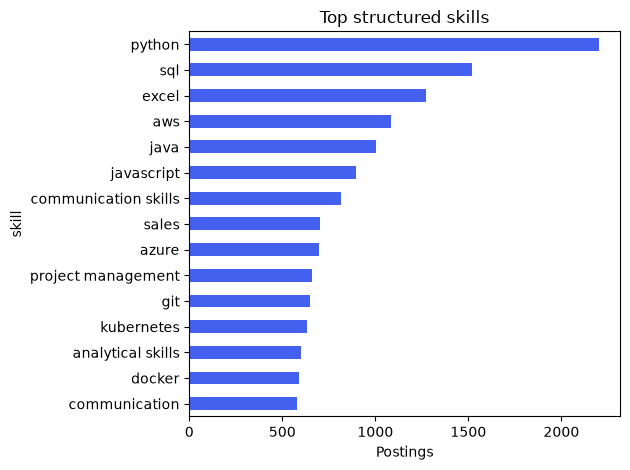

,skill,postings
0,python,2205
1,sql,1522
2,excel,1275
3,aws,1082
4,java,1005
5,javascript,896
6,communication skills,815
7,sales,705
8,azure,696
9,project management,661


In [6]:
top_skills = skill_frequency(india, 15)
ax = top_skills.sort_values('postings').plot.barh(x='skill', y='postings', legend=False, color='#4361ee', title='Top structured skills')
ax.set_xlabel('Postings'); plt.tight_layout(); plt.show()
top_skills

In [7]:
skills_by_role(india, limit=20).rename(columns={'role_clean':'role','skills_list':'skill'})

,role,skill,postings
39340,software-eng,javascript,665
40885,software-eng,python,624
39293,software-eng,java,608
4886,data,python,579
33581,sales,sales,476
5224,data,sql,446
38748,software-eng,git,437
36933,software-eng,aws,426
41861,software-eng,sql,397
40991,software-eng,react,346


## Job market and location analysis

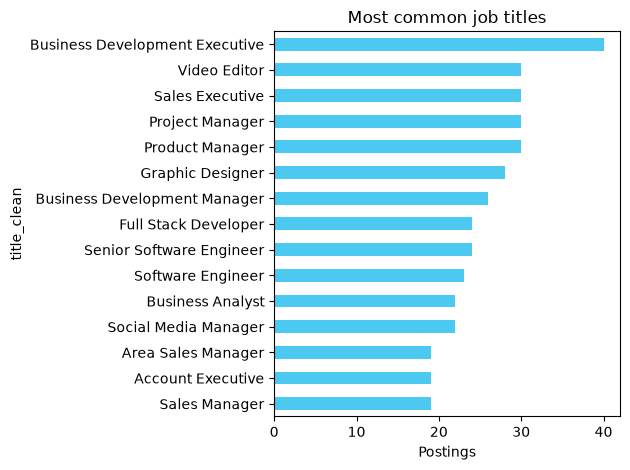

,city_clean,postings
0,Bengaluru,4740
1,Hyderabad,2074
2,Pune,1483
3,Gurugram,1155
4,Chennai,1146
5,Mumbai,1146
6,Delhi,1063
7,Noida,944
8,Ahmedabad,327
9,Kolkata,235


In [8]:
top_titles = india['title_clean'].value_counts().head(15)
top_titles.sort_values().plot.barh(title='Most common job titles', color='#4cc9f0'); plt.xlabel('Postings'); plt.tight_layout(); plt.show()
location_counts(india, limit=15)

## Salary analysis
The source's `salary_annual_usd` values are analysed only as annual USD. Missing salary remains missing; category comparison needs at least three disclosed values.

In [9]:
summary = salary_summary(india)
summary


{'unit': 'Annual USD',
 'total': 19994,
 'disclosed': 1056,
 'disclosure_pct': 5.281584475342603,
 'missing_pct': 94.7184155246574,
 'minimum': np.float64(1200.0),
 'maximum': np.float64(316800.0),
 'median': np.float64(7770.0),
 'mean': np.float64(17080.221590909092)}

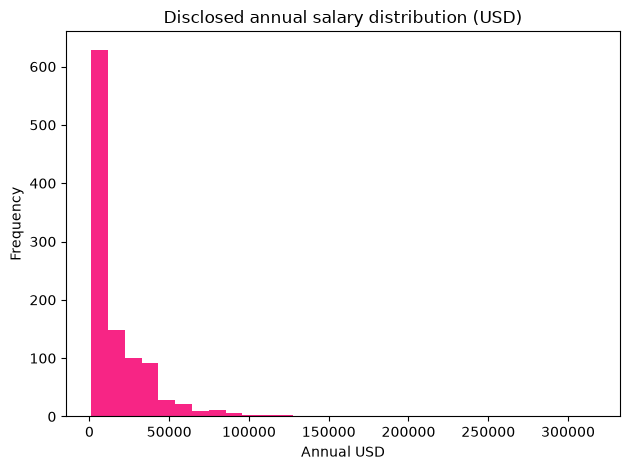

,role_clean,count,median,mean,unit
5,devops-cloud,14,36000.0,46671.428571,Annual USD
12,logistics,18,27000.0,30086.666667,Annual USD
16,product,16,25500.0,23122.500000,Annual USD
3,data,34,23550.0,25685.294118,Annual USD
21,software-eng,117,18000.0,23426.666667,Annual USD
11,legal,6,17100.0,18650.000000,Annual USD
7,finance,53,13200.0,18800.943396,Annual USD
18,sales,184,6030.0,13530.717391,Annual USD
20,security,4,5850.0,10650.000000,Annual USD
4,design,43,5100.0,15883.395349,Annual USD


In [10]:
paid = india['salary_annual_usd'].dropna()
if not paid.empty:
    paid.plot.hist(bins=30, title='Disclosed annual salary distribution (USD)', color='#f72585')
    plt.xlabel('Annual USD'); plt.tight_layout(); plt.show()
salary_by_group(india, 'role_clean').head(15)

## Experience analysis

In [11]:
experience_distribution(india)
print('Entry-level signal:', entry_level_count(india))

Entry-level signal: 2944


## Key findings, limitations and conclusion
Use the calculated tables above for findings. The sample is not the entire Indian market, coverage is January–June 2026, and skills/salary/experience are often absent. Therefore, report frequencies and disclosure coverage alongside every conclusion. See `reports/` for the complete methodology and limitations.